# Reinforcement learning (RNN)

This tutorial uses RNN to train a rocket to land on the surface of a planet.

---


In [ ]:
! pip install gymnasium
! pip install swig
! pip install gymnasium[box2d]

## Introduction

In this tutorial, we introduce Advantage Actor–Critic (A2C), a widely used policy-gradient method in reinforcement learning. A2C belongs to the family of actor–critic algorithms, where two neural networks are trained together. The actor represents the policy and learns to choose actions that maximize expected return, while the critic estimates the value of states and provides a learning signal that stabilizes policy updates. By combining policy optimization with value estimation, A2C often learns more efficiently and stably than pure policy-gradient methods.

In practice, training an A2C agent follows a simple loop. The agent interacts with the environment to collect a short sequence of transitions (state, action, reward). These transitions are then used to compute advantages and update both the actor and critic networks. Over time, the critic learns to estimate how good each state is, while the actor learns to choose actions that lead to higher returns.


---


In [ ]:
# Author: Till Zemann
# License: MIT License

from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl

1.12.0


## Advantage Actor-Critic (A2C)

To illustrate how A2C works, we implement a simple A2C agent from scratch and train it in a reinforcement learning environment. The agent contains two networks: an actor network that outputs action logits defining a probability distribution over actions, and a critic network that predicts the value of the current state. Given a batch of environment states, the forward pass returns both the policy distribution and the estimated state values. During interaction with the environment, the agent samples actions from the policy distribution and records the corresponding log-probabilities, value estimates, and rewards.

The critic network is trained to predict the state-value function V(s), which represents the expected future return from state s. It is trained to minimize the mean squared error between the predicted state values and the actual returns received by the agent. The difference between the return and the predicted value is called the advantage: A(s,a) = Q(s,a) - V(s). Intuitively, the advantage measures whether an action performed better or worse than expected.

The actor network is trained to maximize the expected return by selecting actions that have high expected values according to the critic network.

Training proceeds by collecting short trajectories of experience and then updating the networks using these samples. The actor is optimized using the advantage, which measures how much better an action performs compared to the critic’s baseline prediction. To compute advantages, we use Generalized Advantage Estimation (GAE), a technique that balances bias and variance in the advantage estimates. The overall loss consists of three components: a policy loss for the actor, a value loss for the critic, and an entropy bonus that encourages exploration. Together, these components allow the A2C agent to gradually improve its policy through repeated interaction with the environment.

In the following sections, we will implement the actor and critic networks and train them using the A2C algorithm.

---


In [8]:
class SimpleRNNCell(nn.Module):
    """
    A simple RNN cell implementation.

    Args:
        input_size: The number of input features.
        hidden_size: The number of features in the hidden state.
    """

    def __init__(self, input_size, hidden_size: int, output_size: int) -> None:
        """Initializes the weights and biases of the RNN cell."""
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.input_layer = nn.Linear(input_size, hidden_size)
        std = 1.0 / np.sqrt(hidden_size)
        self.W = nn.Parameter(torch.randn((hidden_size, hidden_size)) * std)
        self.bias = nn.Parameter(torch.zeros((hidden_size,)))
        self.output_layer = nn.Linear(hidden_size, output_size)
        self.act = nn.Tanh()

    def forward(self, input: torch.Tensor, hidden: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the RNN cell.

        Args:
            input: The input tensor with shape (batch_size, input_size).
            hidden: The hidden state tensor with shape (batch_size, hidden_size).

        Returns:
            The next hidden state tensor with shape (batch_size, hidden_size).
        # """
        h = self.act( self.input_layer(input) + hidden@self.W.T + self.bias )
        out = self.output_layer(h)
        return out, h

class A2C(nn.Module):
    """
    (Synchronous) Advantage Actor-Critic agent class

    Args:
        n_features: The number of features of the input state.
        n_actions: The number of actions the agent can take.
        device: The device to run the computations on (running on a GPU might be quicker for larger Neural Nets,
                for this code CPU is totally fine).
        critic_lr: The learning rate for the critic network (should usually be larger than the actor_lr).
        actor_lr: The learning rate for the actor network.
        n_envs: The number of environments that run in parallel (on multiple CPUs) to collect experiences.
    """

    def __init__(
        self,
        n_features: int,
        n_actions: int,
        device: torch.device,
        critic_lr: float,
        actor_lr: float,
        n_envs: int,
        hidden_size: int,
        configuration: str,
    ) -> None:
        """Initializes the actor and critic networks and their respective optimizers."""
        super().__init__()
        self.device = device
        self.n_envs = n_envs

        self.critic = SimpleRNNCell(n_features, hidden_size, 1).to(self.device)
        self.actor = SimpleRNNCell(n_features, hidden_size, n_actions).to(self.device)

        # define optimizers for actor and critic
        self.critic_optim = optim.Adam(self.critic.parameters(), lr=critic_lr)
        self.actor_optim = optim.Adam(self.actor.parameters(), lr=actor_lr)


    def forward(self, x: np.ndarray, hidden: tuple[torch.Tensor, torch.Tensor]) -> tuple[torch.Tensor, torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """
        Forward pass of the networks.

        Args:
            x: A batched vector of states.
            hidden: The hidden state tensor with shape (batch_size, hidden_size).

        Returns:
            state_values: A tensor with the state values, with shape [n_envs,].
            action_logits_vec: A tensor with the action logits, with shape [n_envs, n_actions].
        """
        h_critic, h_actor = hidden
        x = torch.Tensor(x).to(self.device)
        state_values, h_critic = self.critic(x, h_critic)  # shape: [n_envs,]
        action_logits_vec, h_actor = self.actor(x, h_actor)  # shape: [n_envs, n_actions]
        return state_values, action_logits_vec, (h_critic, h_actor)

    def select_action(
        self, x: np.ndarray, hidden: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """
        Returns a tuple of the chosen actions and the log-probs of those actions.

        Args:
            x: A batched vector of states.
            hidden: The hidden state tensor with shape (batch_size, hidden_size).

        Returns:
            actions: A tensor with the actions, with shape [n_steps_per_update, n_envs].
            action_log_probs: A tensor with the log-probs of the actions, with shape [n_steps_per_update, n_envs].
            state_values: A tensor with the state values, with shape [n_steps_per_update, n_envs].
        """
        state_values, action_logits, new_hidden = self.forward(x, hidden)
        action_pd = torch.distributions.Categorical(
            logits=action_logits
        )  # implicitly uses softmax
        actions = action_pd.sample()
        action_log_probs = action_pd.log_prob(actions)
        entropy = action_pd.entropy()
        return actions, action_log_probs, state_values, entropy, new_hidden

    def get_losses(
        self,
        rewards: torch.Tensor,
        action_log_probs: torch.Tensor,
        value_preds: torch.Tensor,
        entropy: torch.Tensor,
        masks: torch.Tensor,
        gamma: float,
        lam: float,
        ent_coef: float,
        device: torch.device,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Computes the loss of a minibatch (transitions collected in one sampling phase) for actor and critic
        using Generalized Advantage Estimation (GAE) to compute the advantages (https://arxiv.org/abs/1506.02438).

        Args:
            rewards: A tensor with the rewards for each time step in the episode, with shape [n_steps_per_update, n_envs].
            action_log_probs: A tensor with the log-probs of the actions taken at each time step in the episode, with shape [n_steps_per_update, n_envs].
            value_preds: A tensor with the state value predictions for each time step in the episode, with shape [n_steps_per_update, n_envs].
            masks: A tensor with the masks for each time step in the episode, with shape [n_steps_per_update, n_envs].
            gamma: The discount factor.
            lam: The GAE hyperparameter. (lam=1 corresponds to Monte-Carlo sampling with high variance and no bias,
                                          and lam=0 corresponds to normal TD-Learning that has a low variance but is biased
                                          because the estimates are generated by a Neural Net).
            device: The device to run the computations on (e.g. CPU or GPU).

        Returns:
            critic_loss: The critic loss for the minibatch.
            actor_loss: The actor loss for the minibatch.
        """
        T = len(rewards)
        advantages = torch.zeros(T, self.n_envs, device=device)

        # compute the advantages using GAE
        gae = 0.0
        for t in reversed(range(T - 1)):
            td_error = (
                rewards[t] + gamma * masks[t] * value_preds[t + 1] - value_preds[t]
            )
            gae = td_error + gamma * lam * masks[t] * gae
            advantages[t] = gae

        # calculate the loss of the minibatch for actor and critic
        critic_loss = advantages.pow(2).mean()

        # give a bonus for higher entropy to encourage exploration
        actor_loss = (
            -(advantages.detach() * action_log_probs).mean() - ent_coef * entropy.mean()
        )
        return (critic_loss, actor_loss)

    def update_parameters(
        self, critic_loss: torch.Tensor, actor_loss: torch.Tensor
    ) -> None:
        """
        Updates the parameters of the actor and critic networks.

        Args:
            critic_loss: The critic loss.
            actor_loss: The actor loss.
        """
        self.critic_optim.zero_grad()
        self.actor_optim.zero_grad()
        loss = critic_loss + actor_loss
        loss.backward()
        self.critic_optim.step()
        self.actor_optim.step()


## Setup
Next we define the training hyperparameters and initialize the environment and the A2C agent.

In [ ]:
# environment hyperparams
n_envs = 10
n_updates = 1000
n_steps_per_update = 128
randomize_domain = False

# agent hyperparams
gamma = 0.999
lam = 0.95  # hyperparameter for GAE
ent_coef = 0.01  # coefficient for the entropy bonus (to encourage exploration)
actor_lr = 0.001
critic_lr = 0.005

hidden_size = 64

env_name = "LunarLander-v3"
envs = gym.make_vec(env_name, num_envs=n_envs, max_episode_steps=600)

obs_shape = envs.single_observation_space.shape[0]
action_shape = envs.single_action_space.n
print(f"obs shape: {obs_shape}, action shape: {action_shape}")
# set the device
use_cuda = False
if use_cuda:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device = torch.device("cpu")

# init the agent
agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)

obs shape: 8, action shape: 4


## Training the A2C Agent

We now train the A2C agent. Training proceeds in repeated sampling phases. In each phase, the agent interacts with the environment for a fixed number of steps to collect transitions. These transitions are then used to compute the actor and critic losses and update the network parameters.

In [ ]:
# For our training loop, we are using the `RecordEpisodeStatistics` wrapper to record the episode lengths and returns and we are also saving
# the losses and entropies to plot them after the agent finished training.
envs_wrapper = gym.wrappers.vector.RecordEpisodeStatistics(
    envs, buffer_length=n_envs * n_updates
)
# torch.autograd.set_detect_anomaly(True)
torch.manual_seed(42)
np.random.seed(42)
critic_losses = np.zeros(n_updates)
actor_losses = np.zeros(n_updates)
entropies = np.zeros(n_updates)
agent.train()
# use tqdm to get a progress bar for training
for sample_phase in tqdm(range(n_updates)):
    # we don't have to reset the envs, they just continue playing
    # until the episode is over and then reset automatically. This is a feature of vectorized environment (gym.make_vec())

    # reset lists that collect experiences of an episode (sample phase)
    ep_value_preds = torch.zeros(n_steps_per_update, n_envs, device=device)
    ep_rewards = torch.zeros(n_steps_per_update, n_envs, device=device)
    ep_action_log_probs = torch.zeros(n_steps_per_update, n_envs, device=device)
    ep_entropy = torch.zeros(n_steps_per_update, n_envs, device=device)
    masks = torch.zeros(n_steps_per_update, n_envs, device=device)

    # at the start of training reset all envs to get an initial state
    if sample_phase == 0:
        states, info = envs_wrapper.reset(seed=42)
        h_critic = torch.zeros((n_envs, hidden_size), device=device)
        h_actor = torch.zeros((n_envs, hidden_size), device=device)
        hidden = (h_critic, h_actor)

    # play n steps in our parallel environments to collect data
    h_critic, h_actor = hidden
    hidden = (h_critic.detach(), h_actor.detach())
    for step in range(n_steps_per_update):
        # select an action A_{t} using S_{t} as input for the agent
        actions, action_log_probs, state_value_preds, entropy, new_hidden = agent.select_action(
            states, hidden
        )

        # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
        states, rewards, terminated, truncated, infos = envs_wrapper.step(
            actions.cpu().numpy()
        )

        ep_value_preds[step] = torch.squeeze(state_value_preds)
        ep_rewards[step] = torch.tensor(rewards, device=device)
        ep_action_log_probs[step] = action_log_probs
        ep_entropy[step] = entropy

        # add a mask (for the return calculation later);
        # for each env the mask is 1 if the episode is ongoing and 0 if it is terminated (not by truncation!)
        done = np.logical_or(terminated, truncated)
        masks[step] = torch.tensor(~done, device=device, dtype=torch.float32)
        done = torch.BoolTensor(done).unsqueeze(1).to(device)
        # masks[step] = torch.tensor([not term for term in terminated])

        # reset hidden state for terminated environments
        h_critic, h_actor = new_hidden
        # done = torch.BoolTensor(terminated).unsqueeze(1).to(device)
        h_critic = torch.where(done, torch.zeros_like(h_critic).to(device), h_critic)
        h_actor = torch.where(done, torch.zeros_like(h_actor).to(device), h_actor)
        hidden = (h_critic, h_actor)
    with torch.no_grad():
        last_v, _, _ = agent.forward(states, hidden)
    ep_value_preds[-1] = torch.squeeze(last_v)  # shape: [n_envs]

    # calculate the losses for actor and critic
    critic_loss, actor_loss = agent.get_losses(
        ep_rewards,
        ep_action_log_probs,
        ep_value_preds,
        ep_entropy,
        masks,
        gamma,
        lam,
        ent_coef,
        device,
    )
    # update the actor and critic networks
    agent.update_parameters(critic_loss, actor_loss)

    # log the losses and entropy
    critic_losses[sample_phase] = critic_loss.detach().cpu().numpy()
    actor_losses[sample_phase] = actor_loss.detach().cpu().numpy()
    entropies[sample_phase] = ep_entropy.detach().mean().cpu().numpy()

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [03:36<00:00,  4.63it/s]


## Plotting
After training, we visualize several metrics to understand how the agent learned. We plot the episode returns (performance), the policy entropy (exploration level), and the actor and critic losses during training.

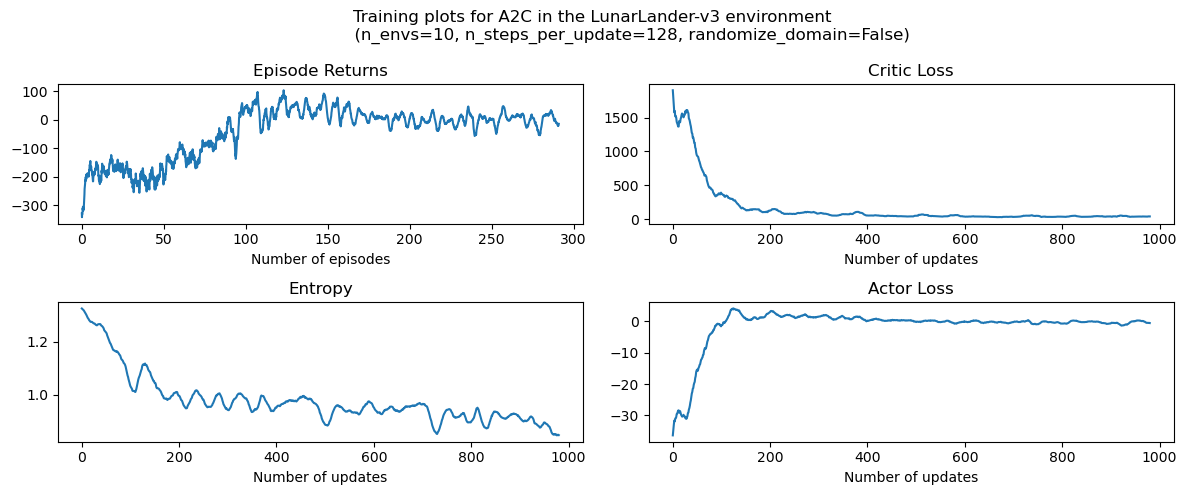

In [ ]:
""" plot the results """

rolling_length = 20
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 5))
fig.suptitle(
    f"Training plots for {agent.__class__.__name__} in the LunarLander-v3 environment \n \
             (n_envs={n_envs}, n_steps_per_update={n_steps_per_update}, randomize_domain={randomize_domain})"
)

# episode return
axs[0][0].set_title("Episode Returns")
episode_returns_moving_average = (
    np.convolve(
        np.array(envs_wrapper.return_queue).flatten(),
        np.ones(rolling_length),
        mode="valid",
    )
    / rolling_length
)
axs[0][0].plot(
    np.arange(len(episode_returns_moving_average)) / n_envs,
    episode_returns_moving_average,
)
axs[0][0].set_xlabel("Number of episodes")

# entropy
axs[1][0].set_title("Entropy")
entropy_moving_average = (
    np.convolve(np.array(entropies), np.ones(rolling_length), mode="valid")
    / rolling_length
)
axs[1][0].plot(entropy_moving_average)
axs[1][0].set_xlabel("Number of updates")


# critic loss
axs[0][1].set_title("Critic Loss")
critic_losses_moving_average = (
    np.convolve(
        np.array(critic_losses).flatten(), np.ones(rolling_length), mode="valid"
    )
    / rolling_length
)
axs[0][1].plot(critic_losses_moving_average)
axs[0][1].set_xlabel("Number of updates")


# actor loss
axs[1][1].set_title("Actor Loss")
actor_losses_moving_average = (
    np.convolve(np.array(actor_losses).flatten(), np.ones(rolling_length), mode="valid")
    / rolling_length
)
axs[1][1].plot(actor_losses_moving_average)
axs[1][1].set_xlabel("Number of updates")

plt.tight_layout()
plt.show()

## Showcase the Agent
Finally, we run a few episodes with rendering enabled to observe how the trained agent behaves.

In [ ]:
""" play a couple of showcase episodes """
n_showcase_episodes = 3
device = 'cpu'
agent.to(device)
agent.eval()
randomize_domain = False
reward_array = np.zeros(n_showcase_episodes)

# create a new sample environment to get new random parameters
env = gym.make("LunarLander-v3", render_mode="human", max_episode_steps=500)

for episode in range(n_showcase_episodes):
    print(f"starting episode {episode}...")
    # get an initial state
    state, info = env.reset()

    # play one episode
    done = False
    hidden = (torch.zeros((1, hidden_size), device=device), torch.zeros((1, hidden_size), device=device))
    rewards = 0.
    while not done:
        # select an action A_{t} using S_{t} as input for the agent
        with torch.no_grad():
            action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)

        # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
        state, reward, terminated, truncated, info = env.step(action.item())
        rewards += reward

        # update if the environment is done
        done = terminated or truncated
        h_critic, h_actor = new_hidden
        h_critic = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_critic).to(device), h_critic)
        h_actor = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_actor).to(device), h_actor)
        hidden = (h_critic, h_actor)
    print(f"Episode {episode} finished with return {rewards}")
    reward_array[episode] = rewards
print(f"Average reward over {n_showcase_episodes} episodes: {np.mean(reward_array)}")
env.close()

starting episode 0...
Episode 0 finished with return 49.64470285390871
starting episode 1...
Episode 1 finished with return 12.076834897480175
starting episode 2...
Episode 2 finished with return 18.427325210484774
Average reward over 3 episodes: 26.716287653957888, std: 16.418817446046337


## References

[1] V. Mnih, A. P. Badia, M. Mirza, A. Graves, T. P. Lillicrap, T. Harley, D. Silver, K. Kavukcuoglu. "Asynchronous Methods for Deep Reinforcement Learning" ICML (2016).

[2] J. Schulman, P. Moritz, S. Levine, M. Jordan and P. Abbeel. "High-dimensional continuous control using generalized advantage estimation." ICLR (2016).

[3] Gymnasium Documentation: Vector environments. (URL: https://gymnasium.farama.org/api/vector/)
